In [1]:
!pip install mlxtend openpyxl

In [3]:
import pandas as pd
from mlxtend.frequent_patterns import fpgrowth, association_rules
import warnings
warnings.filterwarnings('ignore')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [4]:
df = pd.read_excel('Online Retail.xlsx')

print("Shape:", df.shape)
df.info()
df.head()

Shape: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# Simpan statistik sebelum pembersihan
raw_rows = len(df)
raw_invoices = df['InvoiceNo'].nunique()

# Bersihkan deskripsi kosong, transaksi batal (C), dan kuantitas non-positif
df['Description'] = df['Description'].astype(str).str.strip()
df['InvoiceNo'] = df['InvoiceNo'].astype(str)

clean_df = df[
    (df['Description'] != '') & 
    (~df['Description'].str.lower().isin(['nan', 'none'])) &
    (~df['InvoiceNo'].str.startswith('C')) & 
    (df['Quantity'] > 0)
]

# Tampilkan perbandingan sebelum vs sesudah
print(f"Sebelum: {raw_rows:,} baris | {raw_invoices:,} invoice")
print(f"Sesudah: {len(clean_df):,} baris | {clean_df['InvoiceNo'].nunique():,} invoice")

Sebelum: 541,909 baris | 25,900 invoice
Sesudah: 530,693 baris | 20,136 invoice


In [7]:
basket = (clean_df.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum()
          .unstack()
          .fillna(0) > 0)

basket.shape

(20136, 4065)

In [8]:
# Memilih FPGrowth karena cepat pada dimensi besar
frequent_items = fpgrowth(basket, min_support=0.01, use_colnames=True)
frequent_items.sort_values('support', ascending=False).head(10)

,support,itemsets
0,0.112237,(WHITE HANGING HEART T-LIGHT HOLDER)
92,0.103894,(JUMBO BAG RED RETROSPOT)
297,0.098778,(REGENCY CAKESTAND 3 TIER)
587,0.083731,(PARTY BUNTING)
42,0.077672,(LUNCH BAG RED RETROSPOT)
7,0.072259,(ASSORTED COLOUR BIRD ORNAMENT)
617,0.068782,(SET OF 3 CAKE TINS PANTRY DESIGN)
43,0.065554,(PACK OF 72 RETROSPOT CAKE CASES)
174,0.063220,(LUNCH BAG BLACK SKULL.)
79,0.062028,(NATURAL SLATE HEART CHALKBOARD)


In [9]:
rules = association_rules(frequent_items, metric="confidence", min_threshold=0.5)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

# Format kolom agar mudah dibaca untuk laporan
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
top3 = rules[cols].head(3)
top3

,antecedents,consequents,support,confidence,lift
0,(HERB MARKER THYME),"(HERB MARKER ROSEMARY, HERB MARKER PARSLEY)",0.010081,0.856540,80.219959
1,"(HERB MARKER ROSEMARY, HERB MARKER PARSLEY)",(HERB MARKER THYME),0.010081,0.944186,80.219959
2,(HERB MARKER ROSEMARY),"(HERB MARKER THYME, HERB MARKER PARSLEY)",0.010081,0.845833,79.961033


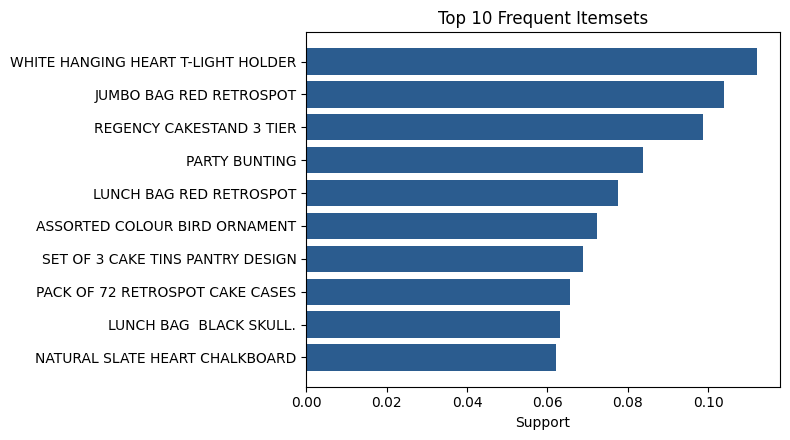

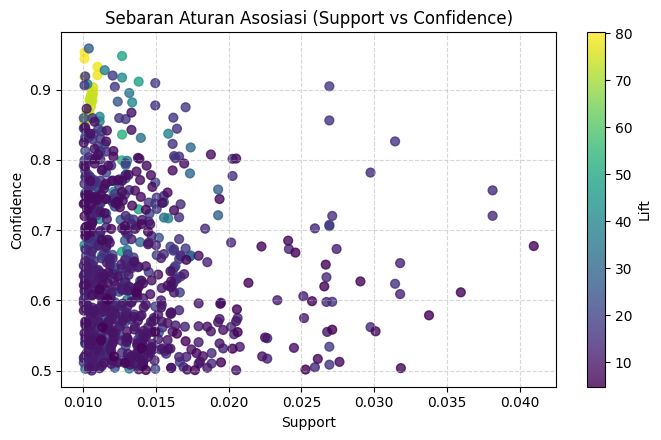

In [10]:
import matplotlib.pyplot as plt

# 1. Bar Chart Top 10 Frequent Itemsets
top10_items = frequent_items.sort_values('support', ascending=False).head(10)
top10_labels = [list(x)[0] for x in top10_items['itemsets']]

plt.figure(figsize=(8, 4.5))
plt.barh(top10_labels[::-1], top10_items['support'][::-1], color='#2b5c8f')
plt.xlabel('Support')
plt.title('Top 10 Frequent Itemsets')
plt.tight_layout()
plt.savefig('top10_frequent_items.png', dpi=300)
plt.show()

# 2. Scatter Plot Support vs Confidence (diwarnai berdasarkan Lift)
plt.figure(figsize=(7, 4.5))
scatter = plt.scatter(rules['support'], rules['confidence'], c=rules['lift'], cmap='viridis', alpha=0.8, s=40)
plt.colorbar(scatter, label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Sebaran Aturan Asosiasi (Support vs Confidence)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('rules_scatter.png', dpi=300)
plt.show()